# Distracted Driver Detection with Vision Transformer (ViT)

This notebook fine-tunes a pre-trained **ViT-Base/16** model to classify distracted drivers into 10 behaviour classes (`c0`–`c9`), all sourced from the **State Farm Distracted Driver** dataset. 
Train, validation, and test splits are all drawn from the same dataset, so this notebook measures **in-distribution** performance.

**Notebook pipeline:**
1. Library setup and imports  
2. Data loading and preprocessing  
3. Model setup (ViT-Base/16)  
4. Training and validation  
5. Test evaluation and performance curves  
6. Explainable AI — Attention Maps and LIME

In [1]:
# pip install torch
# !pip install lime scikit-image
# !pip install --upgrade torchvision timm matplotlib

## 1. Imports

Import the core libraries used throughout this notebook:
- **`timm`** — model hub for loading the pre-trained Vision Transformer  
- **`torchvision`** — image transforms and dataset utilities (`ImageFolder`, `DataLoader`)  
- **`torch.nn`** — loss functions and neural network layers  
- **`matplotlib`** — plotting training curves and image grids

In [2]:
import torch
torch.__version__

'2.10.0'

In [3]:
import matplotlib.pyplot as plt
import torchvision
import timm

from torch import nn
from torchvision import transforms

## 2. Device Configuration

Set the compute device to **GPU** (`cuda`) if available, otherwise fall back to **CPU**. 
Training a ViT on a GPU can be 10–50× faster than on CPU.

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

## 3. Data Preprocessing

Define the transform pipeline applied to every image before it enters the model:

1. **Resize → 224×224** — ViT-Base/16 expects a fixed 224×224 input; each 16×16 patch becomes one token in the transformer sequence  
2. **ToTensor** — converts pixel values from `[0, 255]` integers to `[0.0, 1.0]` float tensors  
3. **Normalize** — subtracts the ImageNet channel means and divides by their standard deviations, matching the distribution the pre-trained weights were fitted on

In [5]:
# Define the transformations
data_transforms = transforms.Compose([
    # 1. Resize the image to 224x224 (This squishes the 640x480 into a square)
    transforms.Resize((224, 224)),
    
    # 2. Convert the image (0-255) to a Tensor (0.0-1.0)
    transforms.ToTensor(),
    
    # 3. Normalize using ImageNet standards
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

## 4. Data Loading

Point to the three splits of the **State Farm Distracted Driver** dataset:
- **Train** — ~15 k images used to update model weights  
- **Val** — ~3 k images used to monitor generalisation after each epoch  
- **Test** — ~3 k held-out images used for final in-distribution evaluation  

`ImageFolder` automatically assigns class labels from sub-directory names (`c0`–`c9`). 
`DataLoader` wraps each split to serve shuffled mini-batches of 32 images during training.

In [ ]:
train_dir = #replace with own path
val_dir = # replace with own path
test_dir = # replace with own path

In [7]:
from torchvision import datasets
from torch.utils.data import DataLoader

# Load datasets with transforms (resizes to 224x224 automatically)
train_dataset = datasets.ImageFolder(root=train_dir, transform=data_transforms)
val_dataset = datasets.ImageFolder(root=val_dir, transform=data_transforms)
test_dataset = datasets.ImageFolder(root=test_dir, transform=data_transforms)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples:   {len(val_dataset)}")
print(f"Test samples:  {len(test_dataset)}")
print(f"Classes: {train_dataset.classes}")

Train samples: 15692
Val samples:   3358
Test samples:  3374
Classes: ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


## 5. Model — ViT-Base/16

Load a **Vision Transformer (ViT-Base/16)** from `timm` with ImageNet pre-trained weights.

- **Architecture:** the input image is split into a 14×14 grid of non-overlapping 16×16-pixel patches. Each patch is linearly projected into a 768-d embedding and fed through 12 transformer encoder blocks.  
- **Classification head:** the `[CLS]` token output passes through a linear layer. Setting `num_classes=10` replaces the original 1000-class ImageNet head with a fresh 10-class head for our driver behaviour categories.  
- The dummy forward pass confirms the output shape is `[1, 10]`.

In [8]:
# Load a pre-trained Vision Transformer (Base model with 16x16 patches)
# 'num_classes=10' automatically replaces the head for you
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=10)

# Verify the output shape
dummy_input = torch.randn(1, 3, 224, 224) 
output = model(dummy_input)
print(output.shape)  # Should be [1, 10]

torch.Size([1, 10])


## 6. Training Configuration

Move the model to the selected device and configure the training components:

- **Loss — `CrossEntropyLoss`:** combines log-softmax and negative log-likelihood; the standard choice for multi-class classification  
- **Optimiser — Adam (lr = 1e-4):** adaptive learning rate optimiser well-suited to fine-tuning large pre-trained models; a small learning rate avoids overwriting the useful pre-trained representations

In [9]:
# Move model to device
model = model.to(device)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print(f"Model on: {device}")
print(f"Optimizer: Adam (lr=1e-4)")
print(f"Loss: CrossEntropyLoss")

Model on: cpu
Optimizer: Adam (lr=1e-4)
Loss: CrossEntropyLoss


## 7. Training Loop

Train for **5 epochs**. Each epoch has two phases:

- **Train:** forward pass → cross-entropy loss → backward pass → Adam weight update. Loss and accuracy are computed per mini-batch and tracked with a `tqdm` progress bar.  
- **Validation:** inference with `torch.no_grad()` (no gradients stored) to monitor generalisation after each epoch.

In [ ]:
from tqdm.notebook import tqdm

NUM_EPOCHS = 5

for epoch in range(NUM_EPOCHS):
    # ---------- Training phase ----------
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    for images, labels in train_bar:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Track metrics
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        # Update progress bar with live metrics
        train_bar.set_postfix(loss=running_loss / (train_bar.n + 1),
                              acc=f"{100.0 * correct / total:.2f}%")

    train_loss = running_loss / len(train_loader)
    train_acc = 100.0 * correct / total

    # ---------- Validation phase ----------
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]  ")
    with torch.no_grad():
        for images, labels in val_bar:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

            val_bar.set_postfix(loss=val_loss / (val_bar.n + 1),
                                acc=f"{100.0 * val_correct / val_total:.2f}%")

    val_loss /= len(val_loader)
    val_acc = 100.0 * val_correct / val_total

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    print("-" * 70)

## 8. Test Set Evaluation

Evaluate the trained model on the **held-out State Farm test split** (~3 k images). 
Because the test set is drawn from the **same distribution** as the training data, we expect high accuracy here — this measures how well the model has learned the task rather than its ability to generalise across datasets.

In [11]:
# ---------- Final Test Evaluation ----------
model.eval()
test_loss = 0.0
test_correct = 0
test_total = 0

test_bar = tqdm(test_loader, desc="Test Evaluation")
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

        test_bar.set_postfix(loss=test_loss / (test_bar.n + 1),
                              acc=f"{100.0 * test_correct / test_total:.2f}%")

test_loss /= len(test_loader)
test_acc = 100.0 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

Test Evaluation:   0%|          | 0/106 [00:00<?, ?it/s]

Test Loss: 0.0645 | Test Acc: 98.40%


## 9. Training Curves

Plot the training and validation **loss** and **accuracy** across the 5 training epochs.

- Converging loss curves confirm the model is learning without obvious overfitting  
- Accuracy plateauing above 97% on the validation set within a few epochs shows the pre-trained ViT features transfer effectively to this task

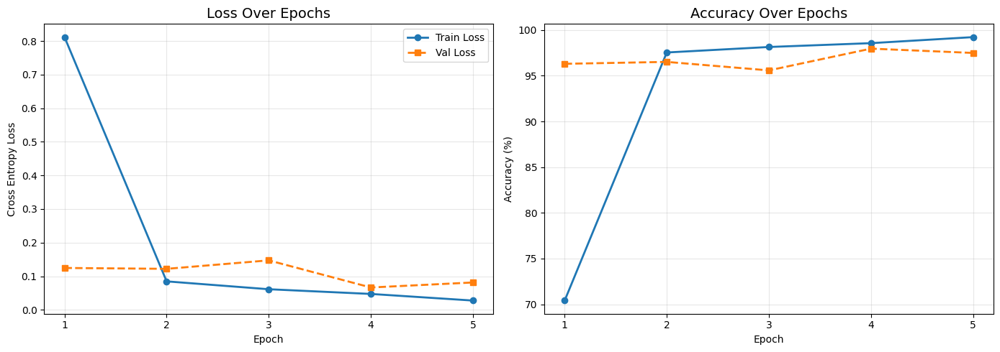

In [12]:
import matplotlib.pyplot as plt

epochs = [1, 2, 3, 4, 5]
train_losses = [0.8115, 0.0847, 0.0613, 0.0473, 0.0276]
val_losses = [0.1246, 0.1220, 0.1472, 0.0665, 0.0814]
train_accs = [70.41, 97.55, 98.15, 98.57, 99.23]
val_accs = [96.31, 96.52, 95.59, 97.97, 97.50]

plt.figure(figsize=(14, 5))

# --- Plot 1: Loss ---
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss', marker='o', linewidth=2)
plt.plot(epochs, val_losses, label='Val Loss', marker='s', linestyle='--', linewidth=2)
plt.title('Loss Over Epochs', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Cross Entropy Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)

# --- Plot 2: Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accs, label='Train Acc', marker='o', linewidth=2)
plt.plot(epochs, val_accs, label='Val Acc', marker='s', linestyle='--', linewidth=2)
plt.title('Accuracy Over Epochs', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(epochs)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Per-class Prediction Visualisation

Display a **10 × 5 grid** of test images — one row per behaviour class (`c0`–`c9`), five samples per row — labelled with the model's prediction:

- **Green title** — correct prediction  
- **Red title** — incorrect prediction (shows true `T:` and predicted `P:` labels)  

Images are de-normalised before display by reversing the ImageNet normalisation applied during preprocessing.

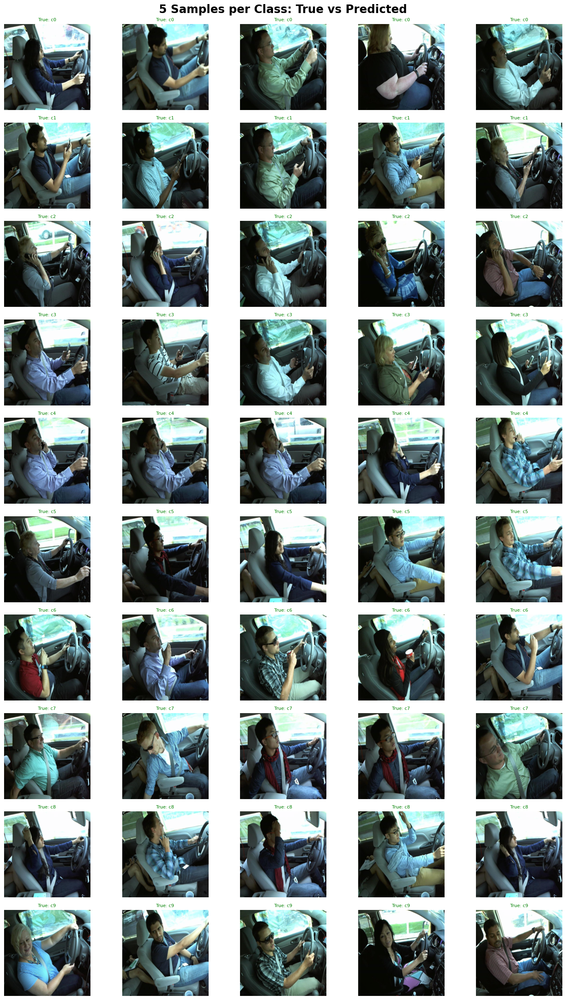

In [13]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# 1. Collect 5 images for each class (c0-c9)
samples_per_class = 5
class_samples = {i: [] for i in range(10)}
total_needed = 10 * samples_per_class

# Iterate through the test_loader
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        for i in range(len(labels)):
            label = labels[i].item()
            if len(class_samples[label]) < samples_per_class:
                # Store the image and the model's prediction for it
                img = images[i].unsqueeze(0).to(device)
                output = model(img)
                _, pred = torch.max(output, 1)
                
                class_samples[label].append({
                    'image': images[i],
                    'prediction': pred.item()
                })
        
        # Stop if we have collected 5 images for every class
        if all(len(v) == samples_per_class for v in class_samples.values()):
            break

# 2. Helper function to un-normalize
def imshow_ax(tensor, ax, title=None, color='black'):
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    if title:
        ax.set_title(title, color=color, fontsize=8)
    ax.axis('off')

# 3. Plotting the grid (10 rows x 5 columns)
fig, axes = plt.subplots(10, 5, figsize=(15, 25))
class_names = test_dataset.classes # ['c0', 'c1', ..., 'c9']

for class_idx in range(10):
    samples = class_samples[class_idx]
    for sample_idx in range(samples_per_class):
        ax = axes[class_idx, sample_idx]
        
        data = samples[sample_idx]
        image = data['image']
        pred_idx = data['prediction']
        
        true_label = class_names[class_idx]
        pred_label = class_names[pred_idx]
        
        # Determine color and text
        if class_idx == pred_idx:
            color = 'green'
            title_text = f"True: {true_label}"
        else:
            color = 'red'
            title_text = f"T:{true_label} P:{pred_label}"
            
        imshow_ax(image, ax, title=title_text, color=color)

plt.tight_layout()
plt.subplots_adjust(top=0.96)
fig.suptitle("5 Samples per Class: True vs Predicted", fontsize=20, fontweight='bold')
plt.show()

## Explainable AI(Attention Map Visualisation & LIME)

In [14]:
!pip install --upgrade opencv-python lime scikit-image scikit-learn scipy

Two complementary XAI methods are used to interpret the model's predictions:

| Method | Type | What it shows |
|---|---|---|
| **Attention Rollout** | Model-specific | Which image patches the ViT's self-attention focuses on |
| **LIME** | Model-agnostic | Which image superpixels most influence the predicted class |

### XAI: Attention Rollout (The "Transformer Grad-CAM")

**How it works:**

1. Disable fused attention so PyTorch can capture intermediate attention weights via a forward hook  
2. Run a forward pass and extract the attention matrix from the **last transformer block**  
3. Average across all 12 attention heads to get a single 14×14 attention map  
4. Extract the row corresponding to the `[CLS]` token — i.e. which patches it attends to  
5. Normalise and up-sample to 224×224, then overlay on the original image as a jet heatmap  

A **10 × 10 grid** is produced: 10 rows (one per class) × 10 columns (5 pairs of original image | attention overlay).

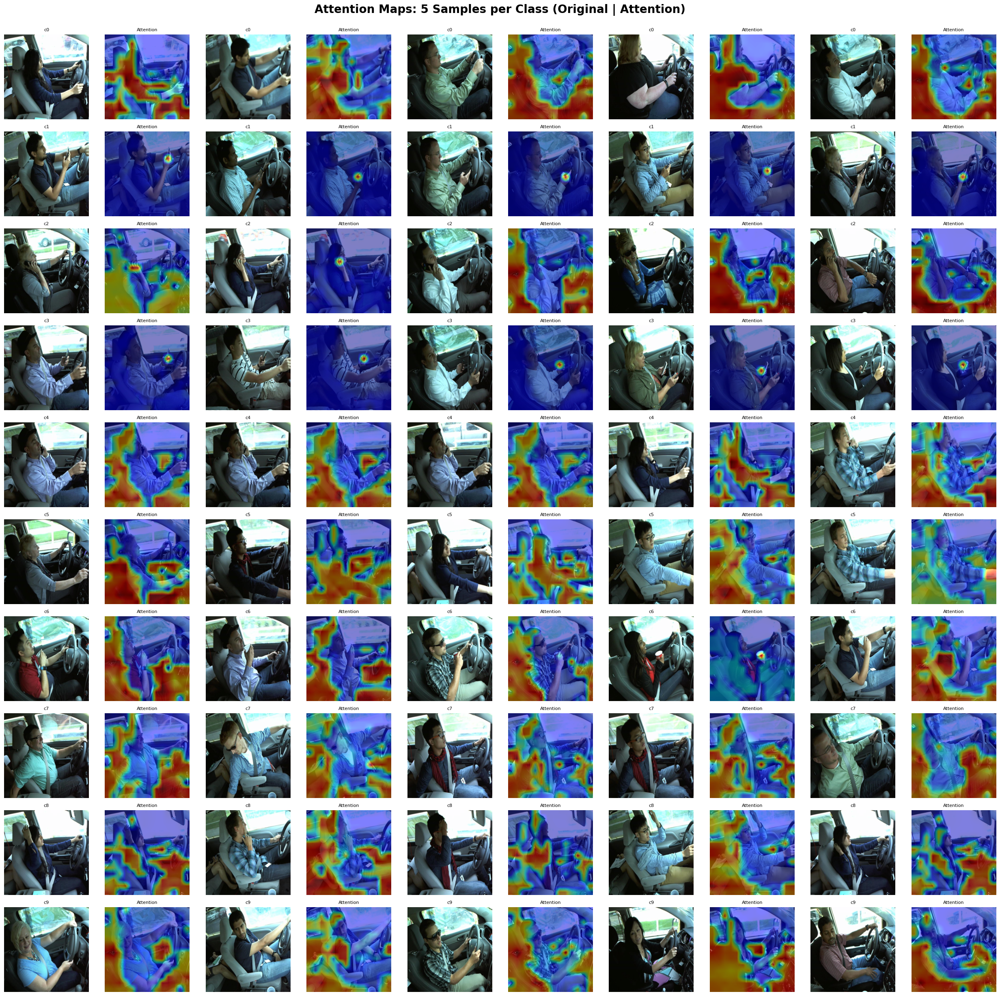

In [15]:
import numpy as np
import cv2

# Disable fused attention so hooks can capture attention weights
for block in model.blocks:
    block.attn.fused_attn = False

def get_attention_map(model, img_tensor):
    """Get the CLS token attention map for a single image."""
    model.eval()
    img_input = img_tensor.unsqueeze(0).to(device)
    
    attention_data = []
    def hook(module, input, output):
        attention_data.append(output)

    handle = model.blocks[-1].attn.attn_drop.register_forward_hook(hook)
    with torch.no_grad():
        _ = model(img_input)
    handle.remove()

    attentions = attention_data[0]
    attentions = attentions.mean(dim=1)
    cls_attn = attentions[0, 0, 1:].reshape(14, 14).cpu().numpy()
    cls_attn = (cls_attn - cls_attn.min()) / (cls_attn.max() - cls_attn.min())
    return cv2.resize(cls_attn, (224, 224))

def denormalize(tensor):
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    return np.clip(img, 0, 1)

# 1. Collect 5 samples per class from test set
samples_per_class = 5
class_samples = {i: [] for i in range(10)}

for images, labels in test_loader:
    for i in range(len(labels)):
        label = labels[i].item()
        if len(class_samples[label]) < samples_per_class:
            class_samples[label].append(images[i])
    if all(len(v) == samples_per_class for v in class_samples.values()):
        break

# 2. Plot grid: 10 rows (classes) x 10 cols (5 pairs of original + attention)
class_names = test_dataset.classes
fig, axes = plt.subplots(10, 10, figsize=(25, 25))

for class_idx in range(10):
    for sample_idx in range(samples_per_class):
        img_tensor = class_samples[class_idx][sample_idx]
        img_display = denormalize(img_tensor)
        attn_mask = get_attention_map(model, img_tensor)

        col_orig = sample_idx * 2
        col_attn = sample_idx * 2 + 1

        # Original image
        ax_orig = axes[class_idx, col_orig]
        ax_orig.imshow(img_display)
        ax_orig.set_title(f"{class_names[class_idx]}", fontsize=8)
        ax_orig.axis('off')

        # Attention overlay
        ax_attn = axes[class_idx, col_attn]
        ax_attn.imshow(img_display)
        ax_attn.imshow(attn_mask, cmap='jet', alpha=0.5)
        ax_attn.set_title("Attention", fontsize=8)
        ax_attn.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
fig.suptitle("Attention Maps: 5 Samples per Class (Original | Attention)", fontsize=20, fontweight='bold')
plt.show()

### LIME Implementation (Model-Agnostic)

**How it works:**

1. Segment the image into superpixels — contiguous regions of similar colour/texture  
2. Randomly mask subsets of superpixels (replace with black) to generate 500 perturbed images  
3. Run the model on all perturbations and record the predicted class probability  
4. Fit a weighted linear model locally to identify which superpixels most increased or decreased prediction confidence  
5. Highlight the **top 5 positive superpixels** in green — the regions the model relies on most  

A **2 × 10 grid** shows the original image (top row) and the LIME explanation (bottom row) for one sample per class.

Generating LIME for class c0...


  0%|          | 0/500 [00:00<?, ?it/s]

Generating LIME for class c1...


  0%|          | 0/500 [00:00<?, ?it/s]

Generating LIME for class c2...


  0%|          | 0/500 [00:00<?, ?it/s]

... (10 outputs left out)

Generating LIME for class c8...


  0%|          | 0/500 [00:00<?, ?it/s]

Generating LIME for class c9...


  0%|          | 0/500 [00:00<?, ?it/s]

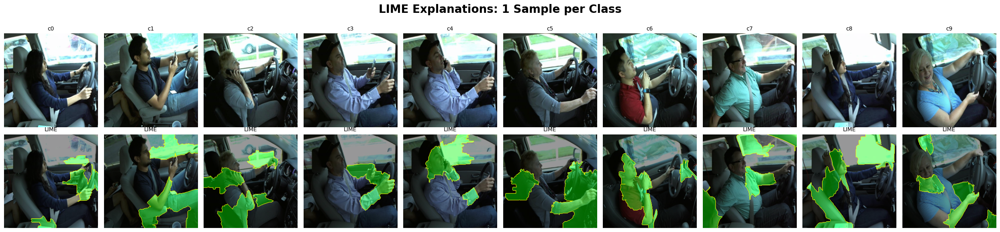

In [16]:
from PIL import Image
from lime import lime_image
from skimage.segmentation import mark_boundaries

# Prediction function for LIME
def batch_predict(images):
    model.eval()
    batch = torch.stack([data_transforms(Image.fromarray(i)) for i in images], dim=0)
    batch = batch.to(device)
    logits = model(batch)
    probs = torch.nn.functional.softmax(logits, dim=1)
    return probs.detach().cpu().numpy()

# Collect 1 sample per class from test set
class_samples = {}
for images, labels in test_loader:
    for i in range(len(labels)):
        label = labels[i].item()
        if label not in class_samples:
            class_samples[label] = images[i]
    if len(class_samples) == 10:
        break

# Generate LIME explanations for all 10 classes
class_names = test_dataset.classes
explainer = lime_image.LimeImageExplainer()

fig, axes = plt.subplots(2, 10, figsize=(25, 6))

for class_idx in range(10):
    img_tensor = class_samples[class_idx]

    # Denormalize for display and LIME input
    img_show = img_tensor.permute(1, 2, 0).numpy()
    img_show = (img_show * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406]
    img_show = (np.clip(img_show, 0, 1) * 255).astype('uint8')

    print(f"Generating LIME for class {class_names[class_idx]}...")
    explanation = explainer.explain_instance(
        img_show,
        batch_predict,
        top_labels=5,
        hide_color=0,
        num_samples=500
    )

    temp, mask = explanation.get_image_and_mask(
        explanation.top_labels[0],
        positive_only=True,
        num_features=5,
        hide_rest=False
    )

    # Row 0: Original image
    axes[0, class_idx].imshow(img_show)
    axes[0, class_idx].set_title(class_names[class_idx], fontsize=10)
    axes[0, class_idx].axis('off')

    # Row 1: LIME explanation with green highlight on attended regions
    lime_display = img_show.astype(np.float32) / 255.0
    green_overlay = np.zeros_like(lime_display)
    green_overlay[mask == 1] = [0, 1, 0]  # Green where LIME says important
    lime_display = lime_display * 0.6 + green_overlay * 0.4
    lime_display = np.clip(lime_display, 0, 1)

    axes[1, class_idx].imshow(mark_boundaries(lime_display, mask))
    axes[1, class_idx].set_title("LIME", fontsize=10)
    axes[1, class_idx].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.88)
fig.suptitle("LIME Explanations: 1 Sample per Class", fontsize=20, fontweight='bold')
plt.show()